In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load the cleaned Netflix dataset
file_path = "/home/richard/Netflix_Fresh/data/cleaned/netflix_cleaned.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nMissing country values:", df["country"].isna().sum())


Dataset loaded successfully!
Dataset shape: (8787, 10)

Missing country values: 287


In [2]:
# Exclude records with missing country information
country_df = df.dropna(subset=["country"]).copy()

# Split entries containing multiple countries
country_df["country"] = country_df["country"].str.split(", ")

# Create one row for each country associated with a title
country_df = country_df.explode("country")

# Count title-country associations
country_counts = country_df["country"].value_counts()

print("Number of unique countries:", country_counts.size)
print("\nTop 10 countries by Netflix title count:")
print(country_counts.head(10))

Number of unique countries: 85

Top 10 countries by Netflix title count:
country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


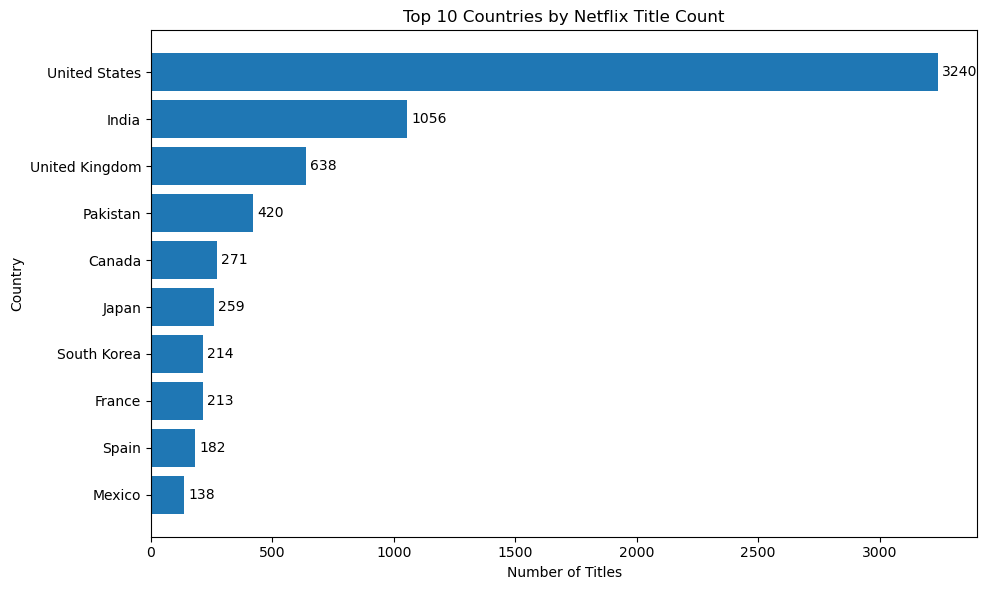

In [3]:
# Select the top 10 countries and sort for a horizontal bar chart
top_10_countries = country_counts.head(10).sort_values()

# Create the chart
plt.figure(figsize=(10, 6))
bars = plt.barh(top_10_countries.index, top_10_countries.values)

# Add chart labels and title
plt.title("Top 10 Countries by Netflix Title Count")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.bar_label(bars, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

In [4]:
# Calculate total title-country associations
total_country_entries = country_counts.sum()

# Calculate the percentage for each of the top 10 countries
top_10_percentages = (
    country_counts.head(10) / total_country_entries
) * 100

print("Top 10 Countries by Percentage of Title-Country Associations")
print(top_10_percentages.round(2).astype(str) + "%")

print("\nTotal title-country associations:", total_country_entries)

Top 10 Countries by Percentage of Title-Country Associations
country
United States     38.12%
India             12.42%
United Kingdom     7.51%
Pakistan           4.94%
Canada             3.19%
Japan              3.05%
South Korea        2.52%
France             2.51%
Spain              2.14%
Mexico             1.62%
Name: count, dtype: object

Total title-country associations: 8500


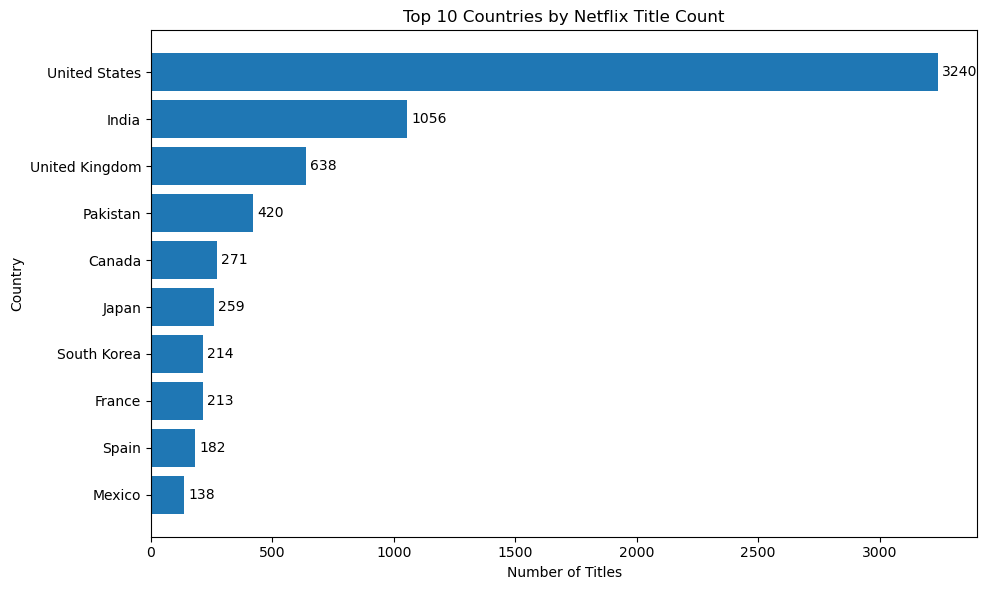

Chart saved successfully!
File location: /home/richard/Netflix_Fresh/outputs/figures/top_10_countries.png


In [5]:
# Define the output directory
output_dir = "/home/richard/Netflix_Fresh/outputs/figures"
os.makedirs(output_dir, exist_ok=True)

# Create and save the chart
plt.figure(figsize=(10, 6))
bars = plt.barh(top_10_countries.index, top_10_countries.values)

plt.title("Top 10 Countries by Netflix Title Count")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.bar_label(bars, fmt="%d", padding=3)

plt.tight_layout()

chart_path = os.path.join(output_dir, "top_10_countries.png")
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully!")
print("File location:", chart_path)

## Business Insights: Country-Wise Netflix Content Analysis

### Key Findings
- **United States:** Leads with 3,240 title-country associations (38.12%).
- **India:** Ranks second with 1,056 associations (12.42%).
- **United Kingdom:** Ranks third with 638 associations (7.51%).
- **Other countries:** Pakistan, Canada, Japan, South Korea, France, Spain, and Mexico complete the top 10.

### Business Recommendations
1. Evaluate content from major contributing countries, particularly the United States and India.
2. Explore opportunities to acquire content from a wider range of countries to support regional diversity.
3. Examine country-specific viewing and engagement data before making investment decisions, because catalog counts alone do not establish audience demand or profitability.

### Conclusion
The analysis shows that Netflix's catalog is strongly represented by content associated with the United States and India. Country-level counts provide a useful overview of catalog distribution, but additional viewing data would be needed to assess content performance.

**Methodological Note:** Titles associated with multiple countries were counted once for each associated country. Therefore, these counts represent title-country associations rather than unique Netflix titles.

In [6]:
# Define the output directory
output_dir = "/home/richard/Netflix_Fresh/outputs"
os.makedirs(output_dir, exist_ok=True)

# Convert country counts into a DataFrame
country_results = country_counts.rename_axis(
    "country"
).reset_index(name="title_country_associations")

# Export results to CSV
csv_path = os.path.join(output_dir, "country_analysis.csv")
country_results.to_csv(csv_path, index=False)

print("Country analysis exported successfully!")
print("Total countries:", len(country_results))
print("Saved to:", csv_path)

Country analysis exported successfully!
Total countries: 85
Saved to: /home/richard/Netflix_Fresh/outputs/country_analysis.csv
